<a href="https://colab.research.google.com/github/poornimaAK5/aiproject/blob/main/Unsupervised_Learning_%E2%80%93_Patient_Segmentation_using_K_Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

df = pd.read_csv(url)


In [ ]:
df.shape

(768, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
X = df.drop("Outcome", axis=1)  # df = df.drop("Outcome", axis=1)

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
wcss = []

for i in range(1,11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

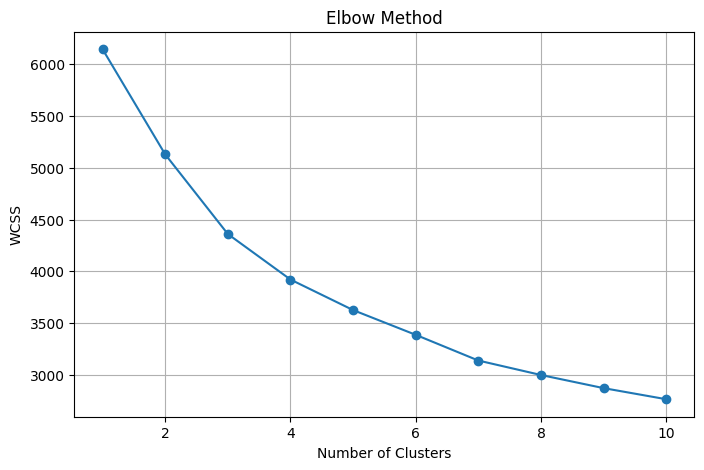

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

In [ ]:
df["Cluster"] = clusters

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Cluster
0,6,148,72,35,0,33.6,0.627,50,1,2
1,1,85,66,29,0,26.6,0.351,31,0,1
2,8,183,64,0,0,23.3,0.672,32,1,2
3,1,89,66,23,94,28.1,0.167,21,0,1
4,0,137,40,35,168,43.1,2.288,33,1,0


In [ ]:
df["Cluster"].value_counts()

,count
Cluster,
1,337
0,216
2,215


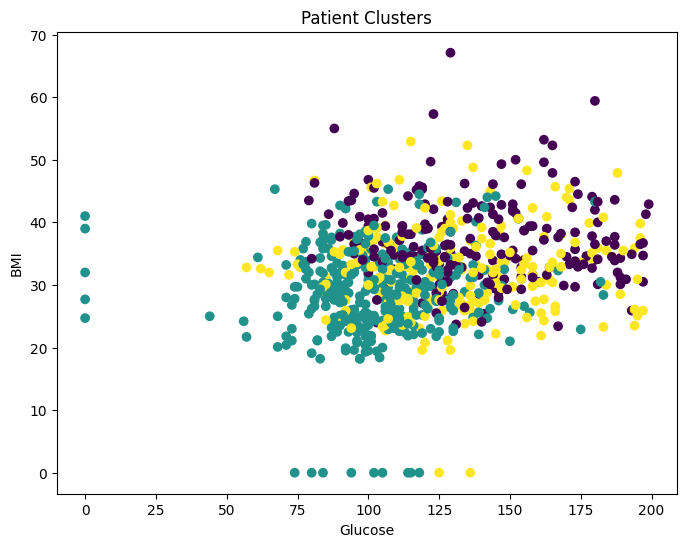

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["Glucose"],
    df["BMI"],
    c=df["Cluster"]
)

plt.xlabel("Glucose")

plt.ylabel("BMI")

plt.title("Patient Clusters")

plt.show()

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import numpy as np
import pickle

In [ ]:
with open("kmeans_model.pkl","rb") as f:
    model = pickle.load(f)

with open("scaler.pkl","rb") as f:
    scaler = pickle.load(f)

print("✅ Model Loaded Successfully")

FileNotFoundError: [Errno 2] No such file or directory: 'kmeans_model.pkl'

In [ ]:
cluster_info = {
    0:{
        "group":"Healthy Lifestyle Group",
        "risk":"🟢 Low Risk",
        "description":"Patients in this cluster generally have healthier medical characteristics.",
        "recommendation":"Maintain healthy diet, exercise regularly and attend annual health checkups."
    },

    1:{
        "group":"Moderate Monitoring Group",
        "risk":"🟡 Moderate Risk",
        "description":"Patients show moderate diabetes related characteristics.",
        "recommendation":"Monitor blood glucose regularly and improve lifestyle habits."
    },

    2:{
        "group":"High Attention Group",
        "risk":"🔴 High Risk",
        "description":"Patients have characteristics associated with higher diabetes risk.",
        "recommendation":"Consult a healthcare professional and follow medical advice."
    }
}

In [ ]:
def predict_cluster(
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    pedigree,
    age
):

    # Patient Data
    patient = np.array([[
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        pedigree,
        age
    ]])

    # Scale Input
    patient_scaled = scaler.transform(patient)

    # Predict Cluster
    cluster_id = int(model.predict(patient_scaled)[0])

    # Patient Summary
    summary = f"""
👤 PATIENT SUMMARY

━━━━━━━━━━━━━━━━━━━━━━━━━━

Age                 : {age} Years

Pregnancies         : {pregnancies}

Glucose             : {glucose}

Blood Pressure      : {blood_pressure}

Skin Thickness      : {skin_thickness}

Insulin             : {insulin}

BMI                 : {bmi}

Pedigree Function   : {pedigree}

━━━━━━━━━━━━━━━━━━━━━━━━━━

Assigned Cluster    : Cluster {cluster_id}

Risk Level          : {cluster_info[cluster_id]["risk"]}

Patient Group       : {cluster_info[cluster_id]["group"]}
"""

    return (
        f"Cluster {cluster_id}",
        cluster_info[cluster_id]["group"],
        cluster_info[cluster_id]["risk"],
        cluster_info[cluster_id]["description"],
        cluster_info[cluster_id]["recommendation"],
        summary
    )

In [ ]:
# ================================
# PROFESSIONAL GRADIO UI
# ================================

with gr.Blocks(
    title="AI Diabetes Patient Segmentation System"
) as demo:

    gr.Markdown("""
# 🏥 AI-Based Diabetes Patient Segmentation & Risk Analysis System

### 📊 Unsupervised Machine Learning using K-Means Clustering
""")

    with gr.Row():

        # ---------------- LEFT COLUMN ----------------

        with gr.Column(scale=1):

            gr.Markdown("## 📝 Patient Information")

            pregnancies = gr.Slider(
                0,20,
                value=2,
                label="Pregnancies"
            )

            glucose = gr.Slider(
                0,200,
                value=120,
                label="Glucose"
            )

            blood_pressure = gr.Slider(
                0,140,
                value=70,
                label="Blood Pressure"
            )

            skin_thickness = gr.Slider(
                0,100,
                value=25,
                label="Skin Thickness"
            )

            insulin = gr.Slider(
                0,900,
                value=100,
                label="Insulin"
            )

            bmi = gr.Slider(
                10,60,
                value=30.5,
                label="BMI"
            )

            pedigree = gr.Slider(
                0,3,
                value=0.45,
                label="Diabetes Pedigree Function"
            )

            age = gr.Slider(
                18,90,
                value=35,
                label="Age"
            )

            analyze = gr.Button(
                "🔍 Analyze Patient",
                variant="primary",
                size="lg"
            )

            clear = gr.ClearButton(
                value="🗑️ Clear All"
            )

        # ---------------- RIGHT COLUMN ----------------

        with gr.Column(scale=1):

            gr.Markdown("## 🤖 AI Analysis")

            cluster = gr.Textbox(
                label="Assigned Cluster"
            )

            group = gr.Textbox(
                label="Patient Group"
            )

            risk = gr.Textbox(
                label="Risk Level"
            )

            description = gr.Textbox(
                label="Cluster Description",
                lines=4
            )

            recommendation = gr.Textbox(
                label="Recommendation",
                lines=4
            )

            summary = gr.Textbox(
                label="Patient Summary",
                lines=8
            )

            gr.Markdown("""
### 📌 Project Information

**Algorithm**
- K-Means Clustering

**Learning Type**
- Unsupervised Learning

**Dataset**
- PIMA Indians Diabetes Dataset

**Features**
- 8 Medical Features

**Clusters**
- 3 Patient Groups
""")

    analyze.click(
        fn=predict_cluster,

        inputs=[
            pregnancies,
            glucose,
            blood_pressure,
            skin_thickness,
            insulin,
            bmi,
            pedigree,
            age
        ],

        outputs=[
            cluster,
            group,
            risk,
            description,
            recommendation,
            summary
        ]
    )

    gr.Markdown("""

---

### 👨‍💻 Developed Using

- Python
- Machine Learning
- K-Means Clustering
- Scikit-Learn
- Gradio

**⚠ Educational Purpose Only**
""")

demo.launch(
    share=True,
    debug=False,
    show_error=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8fbd09830270bd55f3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
